# Sub-etapa 1.3 · Implementación y entrenamiento de modelos: Random Forest y XGBoost

**Proyecto:** Análisis de marcha y clasificación de riesgo de caída en adultos mayores (Línea 1, Proyecto 1).

**Objetivo de este notebook:** entrenar los dos modelos que trabajan con variables calculadas, **Random Forest** y **XGBoost**, usando el dataset limpio de la sub-etapa 1.2 (`labwalks_modelo.csv`), evaluarlos con validación cruzada y guardarlos (*checkpoints*) para no tener que entrenarlos de nuevo. La LSTM, que trabaja con las señales, va en un notebook aparte.

**Productos que genera:**

| Archivo | Contenido |
|---|---|
| `resultados/metricas_modelos.csv` | Métricas promedio de cada modelo (media ± desviación estándar) |
| `resultados/metricas_por_particion.csv` | Métricas de cada partición de la validación cruzada |
| `modelos/random_forest.joblib`, `modelos/xgboost.joblib` | Modelos entrenados (checkpoints) |
| `modelos/info_modelos.json` | Variables usadas, parámetros, versiones y fecha |
| `figuras/modelos_*.png` | Gráficos para el informe |

**Cómo ejecutarlo:** *Kernel → Restart Kernel and Run All Cells*. Tarda unos minutos, porque cada modelo se entrena 50 veces.

**Con qué datos entrenar:** el parámetro `DATOS` de la configuración elige la tabla de entrada: `"laboratorio"` (caminatas de 1 minuto, notebook 01), `"vida_diaria"` (registros de 3 días, notebook 01b) o `"combinado"` (ambas). Para comparar, ejecuta el notebook una vez con cada opción: los resultados se guardan con el nombre de la opción al final (por ejemplo `metricas_modelos_vida_diaria.csv`) y no se sobrescriben.

## 1. Configuración

Librerías nuevas para esta etapa (una vez, en la terminal de Anaconda):

```
pip install scikit-learn xgboost joblib
```

In [1]:
import json
import platform
from datetime import datetime
from pathlib import Path

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import xgboost
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, confusion_matrix, f1_score, make_scorer,
                             recall_score)
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_val_predict, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

# --- Rutas ------------------------------------------------------------------
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESADOS = RAIZ / "datos" / "procesados"
MODELOS = RAIZ / "modelos"
RESULTADOS = RAIZ / "resultados"
FIGURAS = RAIZ / "figuras"
for carpeta in (MODELOS, RESULTADOS, FIGURAS):
    carpeta.mkdir(parents=True, exist_ok=True)

# --- Datos de entrada ---------------------------------------------------------
# "laboratorio" = caminatas de 1 minuto (notebook 01)
# "vida_diaria" = tramos de marcha de los registros de 3 días (notebook 01b)
# "combinado"   = ambas, para las personas que están en las dos bases (notebook 01b)
DATOS = "laboratorio"
ARCHIVOS = {"laboratorio": "labwalks_modelo.csv", "vida_diaria": "vida_diaria_modelo.csv",
            "combinado": "combinado_modelo.csv"}
SUFIJO = "" if DATOS == "laboratorio" else f"_{DATOS}"   # así los resultados de cada opción no se sobrescriben

# --- Validación ---------------------------------------------------------------
SEMILLA = 42             # la misma de la sub-etapa 1.2
N_PARTICIONES = 5        # validación cruzada de 5 partes
N_REPETICIONES = 10      # se repite 10 veces con distinto orden: 50 entrenamientos por modelo

np.random.seed(SEMILLA)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print(f"Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | xgboost {xgboost.__version__} | matplotlib {matplotlib.__version__}")

Python 3.14.6 | numpy 2.4.6 | pandas 3.0.3 | scikit-learn 1.9.0 | xgboost 3.4.1 | matplotlib 3.11.0


## 2. Datos

Se usa la tabla que dejó la sub-etapa 1.2: una fila por persona, la etiqueta `cae` (1 = cae, 0 = no cae) y las variables de marcha sin redundancias. Como **cada persona aparece una sola vez**, cualquier división de la tabla separa automáticamente por sujeto: nunca queda la misma persona en entrenamiento y en prueba, que es la fuga de datos que advierte la literatura.

In [2]:
datos = pd.read_csv(PROCESADOS / ARCHIVOS[DATOS])
datos["clave"] = datos["registro"].str[:5].str.lower()     # co001, fl001...: une laboratorio y vida diaria
VARIABLES = [c for c in datos.columns if c not in ("registro", "clave", "grupo", "cae")]
print(f"Datos: {DATOS} ({ARCHIVOS[DATOS]})")
X = datos[VARIABLES]
y = datos["cae"].astype(int)

print(f"Personas: {len(datos)}  |  caen: {y.sum()}  |  no caen: {(y == 0).sum()}  "
      f"({100 * y.mean():.0f} % de la clase 'cae')")
print(f"Variables de entrada ({len(VARIABLES)}): {', '.join(VARIABLES)}")
print(f"Valores faltantes: {int(X.isna().sum().sum())}")
X.describe().T.round(3)

Datos: combinado (combinado_modelo.csv)
Personas: 62  |  caen: 27  |  no caen: 35  (44 % de la clase 'cae')
Variables de entrada (30): cadencia_pasos_min_lab, cv_tiempo_paso_pct_lab, cv_tiempo_zancada_pct_lab, regularidad_paso_lab, regularidad_zancada_lab, simetria_lab, frec_dominante_hz_lab, amplitud_dominante_lab, ancho_pico_hz_lab, rms_acc_ml_lab, rms_acc_ap_lab, rms_giro_yaw_lab, rms_giro_pitch_lab, rms_giro_roll_lab, cadencia_pasos_min_vd, cv_tiempo_paso_pct_vd, cv_tiempo_zancada_pct_vd, regularidad_paso_vd, regularidad_zancada_vd, simetria_vd, frec_dominante_hz_vd, amplitud_dominante_vd, ancho_pico_hz_vd, rms_acc_ap_vd, rms_acc_ml_vd, rms_giro_pitch_vd, rms_giro_roll_vd, rms_giro_yaw_vd, minutos_marcha_dia_vd, duracion_media_tramo_s_vd
Valores faltantes: 0


,count,mean,std,min,25%,50%,75%,max
cadencia_pasos_min_lab,62.0,112.476,8.770,95.464,105.960,112.255,116.226,136.502
cv_tiempo_paso_pct_lab,62.0,8.211,4.109,3.416,5.650,7.438,9.424,27.578
cv_tiempo_zancada_pct_lab,62.0,5.225,3.222,2.012,3.283,4.430,5.960,21.700
regularidad_paso_lab,62.0,0.720,0.131,0.226,0.652,0.763,0.806,0.885
regularidad_zancada_lab,62.0,0.702,0.122,0.196,0.657,0.729,0.776,0.885
simetria_lab,62.0,1.032,0.136,0.553,0.957,1.031,1.118,1.297
frec_dominante_hz_lab,62.0,1.880,0.163,1.562,1.770,1.868,1.953,2.368
amplitud_dominante_lab,62.0,0.167,0.143,0.002,0.076,0.117,0.218,0.617
ancho_pico_hz_lab,62.0,0.180,0.021,0.159,0.171,0.171,0.183,0.269
rms_acc_ml_lab,62.0,0.131,0.030,0.070,0.108,0.134,0.147,0.220


## 3. Cómo se evalúan los modelos

**Validación cruzada estratificada repetida.** Los datos se dividen en 5 partes con la misma proporción de personas que caen. Se entrena con 4 partes y se prueba con la que quedó fuera, rotando hasta que cada parte se usó una vez para probar. Esto se repite 10 veces con un orden distinto, así que cada modelo se entrena y se prueba 50 veces. Con solo 72 personas, una única división daría un resultado que depende mucho de la suerte; promediar 50 pruebas da una estimación más estable y permite informar su variación.

**Métricas** (como se definieron en el marco teórico):

| Métrica | Qué mide |
|---|---|
| Exactitud | Porcentaje de personas bien clasificadas |
| Sensibilidad | De quienes caen, cuántos detecta el modelo (lo más importante para prevenir) |
| Especificidad | De quienes no caen, cuántos reconoce como tales |
| F1-score | Combina sensibilidad y precisión en un solo número |
| AUC | Qué tan bien separa las dos clases: 0,5 = al azar, 1,0 = perfecto |

**Datos faltantes.** Si alguna variable falta, se reemplaza por la mediana calculada **solo con los datos de entrenamiento** de cada partición (por eso va dentro del `pipeline`), para no filtrar información de prueba.

In [3]:
validacion = RepeatedStratifiedKFold(n_splits=N_PARTICIONES, n_repeats=N_REPETICIONES, random_state=SEMILLA)
METRICAS = {
    "exactitud": "accuracy",
    "sensibilidad": "recall",
    "especificidad": make_scorer(recall_score, pos_label=0),
    "f1": make_scorer(f1_score, zero_division=0),
    "auc": "roc_auc",
}


def evaluar(nombre, modelo, X_entrada):
    r = cross_validate(modelo, X_entrada, y, cv=validacion, scoring=METRICAS, n_jobs=-1)
    por_particion = pd.DataFrame({m: r[f"test_{m}"] for m in METRICAS})
    por_particion.insert(0, "modelo", nombre)
    return por_particion


resultados = []   # aquí se van juntando todos los modelos

## 4. Puntos de comparación

Un modelo solo es útil si supera a alternativas simples. Siguiendo las decisiones del marco teórico, se usan tres referencias:

1. **Sin modelo:** un clasificador que no mira los datos y responde siempre la clase más frecuente (con las caminatas de laboratorio, "no cae"). Su AUC es 0,5: es el piso que cualquier modelo debe superar.
2. **Una sola variable de marcha:** regresión logística con la frecuencia dominante, la única variable significativa en el EDA. Responde la pregunta: *¿vale la pena un modelo complejo, o basta con medir el ritmo de la marcha?*
3. **TUG:** regresión logística con el tiempo del Timed Up and Go de la planilla clínica, la prueba que se usa hoy en la práctica.

In [4]:
resultados.append(evaluar("Sin modelo", DummyClassifier(strategy="prior"), X))

variable_simple = next((v for v in VARIABLES if v.startswith("frec_dominante")), VARIABLES[0])
regresion = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression())
resultados.append(evaluar(f"Solo {variable_simple}", regresion, X[[variable_simple]]))

# TUG desde el dataset completo de la 1.2 (tiene las columnas de la planilla clínica)
completo = pd.read_csv(PROCESADOS / "labwalks_variables.csv")
col_tug = next((c for c in completo.columns if c.strip().upper() == "TUG"), None)
if col_tug is not None:
    completo["clave"] = completo["registro"].str[:5].str.lower()
    tug = datos[["clave"]].merge(completo[["clave", col_tug]], on="clave", how="left")[[col_tug]]
    tug[col_tug] = pd.to_numeric(tug[col_tug], errors="coerce")
    print(f"TUG disponible en {tug[col_tug].notna().sum()} de {len(tug)} personas "
          f"(las que faltan se completan con la mediana de entrenamiento)")
    resultados.append(evaluar("Solo TUG", regresion, tug))
else:
    print("No se encontró la columna TUG; se omite esta referencia.")

TUG disponible en 62 de 62 personas (las que faltan se completan con la mediana de entrenamiento)


## 5. Random Forest

Entrena muchos árboles de decisión, cada uno con una muestra al azar de personas y variables, y decide por votación. Es el modelo más simple de usar y suele funcionar bien con pocos datos.

Parámetros elegidos (se dejan casi todos por defecto para no ajustar de más con 72 personas; su ajuste fino queda para la sub-etapa 1.4):

* `n_estimators=500`: 500 árboles, suficientes para que el resultado sea estable.
* `min_samples_leaf=2`: cada hoja necesita al menos 2 personas, para que los árboles no memoricen casos aislados.
* `class_weight="balanced"`: da el mismo peso a ambas clases aunque haya una persona más en un grupo.

In [5]:
random_forest = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestClassifier(n_estimators=500, min_samples_leaf=2, class_weight="balanced",
                           random_state=SEMILLA, n_jobs=-1),
)
resultados.append(evaluar("Random Forest", random_forest, X))
resultados[-1].describe().loc[["mean", "std"]].round(3)

,exactitud,sensibilidad,especificidad,f1,auc
mean,0.616,0.523,0.689,0.528,0.618
std,0.099,0.194,0.149,0.154,0.145


## 6. XGBoost

También usa árboles, pero los construye uno tras otro: cada árbol nuevo corrige los errores de los anteriores. Suele rendir mejor que Random Forest, pero se sobreajusta con más facilidad, por eso se usan árboles poco profundos y un aprendizaje lento.

* `n_estimators=300`, `learning_rate=0.05`: muchos árboles pequeños que aprenden de a poco.
* `max_depth=3`: árboles poco profundos, adecuados para pocos datos.
* `subsample=0.8`, `colsample_bytree=0.8`: cada árbol ve el 80 % de las personas y de las variables, lo que reduce el sobreajuste.

In [6]:
xgb = make_pipeline(
    SimpleImputer(strategy="median"),
    XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8, colsample_bytree=0.8,
                  eval_metric="logloss", random_state=SEMILLA, n_jobs=1),
)
resultados.append(evaluar("XGBoost", xgb, X))
resultados[-1].describe().loc[["mean", "std"]].round(3)

,exactitud,sensibilidad,especificidad,f1,auc
mean,0.559,0.386,0.691,0.418,0.548
std,0.102,0.171,0.169,0.156,0.142


## 7. Comparación de resultados

La tabla muestra el promedio y la desviación estándar de las 50 pruebas. La desviación indica cuánto cambia el resultado según qué personas quedan en la prueba: con muestras pequeñas suele ser grande, y es importante informarla.

In [7]:
por_particion = pd.concat(resultados, ignore_index=True)
por_particion.to_csv(RESULTADOS / f"metricas_por_particion{SUFIJO}.csv", index=False)

orden = list(dict.fromkeys(por_particion["modelo"]))
resumen = por_particion.groupby("modelo")[list(METRICAS)].agg(["mean", "std"]).reindex(orden)
tabla = pd.DataFrame({m: [f"{resumen.loc[i, (m, 'mean')]:.3f} ± {resumen.loc[i, (m, 'std')]:.3f}" for i in orden]
                      for m in METRICAS}, index=orden)
resumen.columns = [f"{m}_{e}" for m, e in resumen.columns]
resumen.to_csv(RESULTADOS / f"metricas_modelos{SUFIJO}.csv")
tabla

,exactitud,sensibilidad,especificidad,f1,auc
Sin modelo,0.565 ± 0.022,0.000 ± 0.000,1.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000
Solo frec_dominante_hz_lab,0.684 ± 0.098,0.504 ± 0.177,0.823 ± 0.140,0.567 ± 0.176,0.703 ± 0.133
Solo TUG,0.642 ± 0.128,0.306 ± 0.174,0.903 ± 0.164,0.414 ± 0.203,0.628 ± 0.169
Random Forest,0.616 ± 0.099,0.523 ± 0.194,0.689 ± 0.149,0.528 ± 0.154,0.618 ± 0.145
XGBoost,0.559 ± 0.102,0.386 ± 0.171,0.691 ± 0.169,0.418 ± 0.156,0.548 ± 0.142


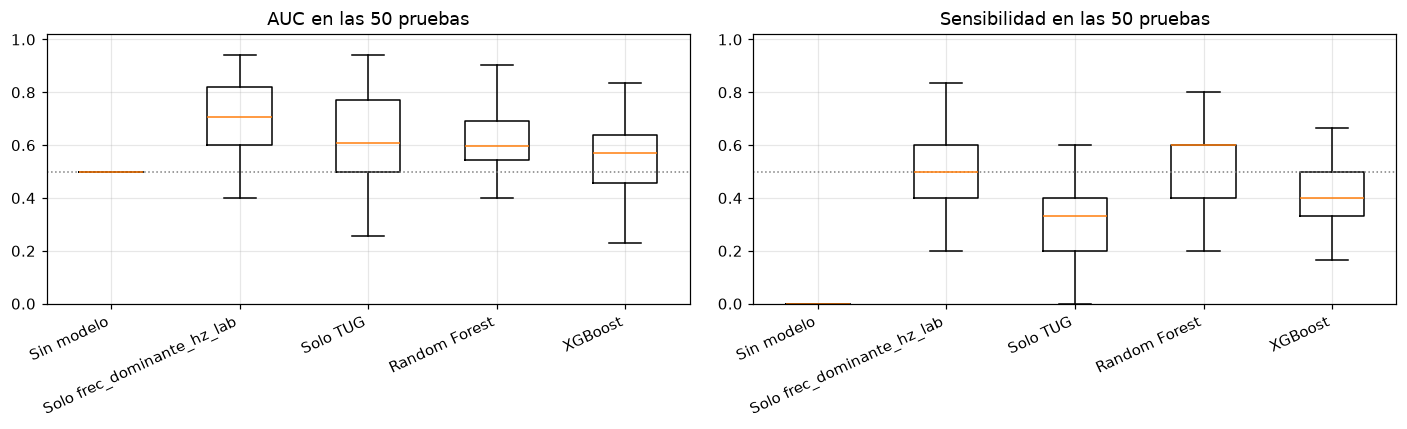

In [8]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
for eje, metrica in zip(ejes, ["auc", "sensibilidad"]):
    datos_m = [por_particion.loc[por_particion["modelo"] == m, metrica] for m in orden]
    eje.boxplot(datos_m, widths=0.5, showfliers=False)
    eje.set_xticks(range(1, len(orden) + 1), orden, rotation=25, ha="right")
    eje.axhline(0.5, color="gray", ls=":", lw=1)
    eje.set(title=f"{'AUC' if metrica == 'auc' else metrica.capitalize()} en las {len(datos_m[0])} pruebas", ylim=(0, 1.02))
fig.tight_layout()
fig.savefig(FIGURAS / f"modelos_comparacion{SUFIJO}.png", dpi=150)

### 7.1 Curva ROC y matriz de confusión

Para estos gráficos se usa una sola validación cruzada de 5 partes: cada persona recibe una predicción hecha por un modelo que **no la vio** al entrenar. La curva ROC muestra el equilibrio entre detectar a quienes caen y no dar falsas alarmas; la matriz de confusión cuenta aciertos y errores con el umbral habitual de 0,5.

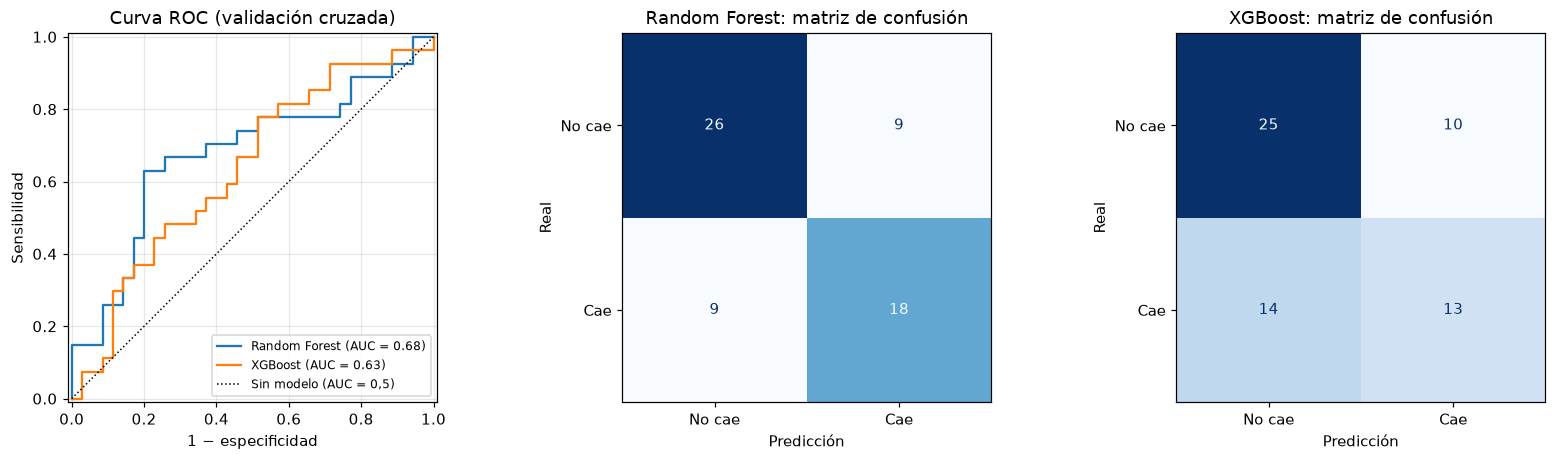

In [9]:
una_vez = StratifiedKFold(n_splits=N_PARTICIONES, shuffle=True, random_state=SEMILLA)
probabilidades = {nombre: cross_val_predict(modelo, X, y, cv=una_vez, method="predict_proba")[:, 1]
                  for nombre, modelo in [("Random Forest", random_forest), ("XGBoost", xgb)]}

fig, ejes = plt.subplots(1, 3, figsize=(15, 4.3))
for nombre, p in probabilidades.items():
    RocCurveDisplay.from_predictions(y, p, name=nombre, ax=ejes[0])
ejes[0].plot([0, 1], [0, 1], "k:", lw=1, label="Sin modelo (AUC = 0,5)")
ejes[0].set(title="Curva ROC (validación cruzada)", xlabel="1 − especificidad", ylabel="Sensibilidad")
ejes[0].legend(loc="lower right", fontsize=8)
for eje, (nombre, p) in zip(ejes[1:], probabilidades.items()):
    ConfusionMatrixDisplay(confusion_matrix(y, (p >= 0.5).astype(int)), display_labels=["No cae", "Cae"]).plot(
        ax=eje, colorbar=False, cmap="Blues")
    eje.set(title=f"{nombre}: matriz de confusión", xlabel="Predicción", ylabel="Real")
    eje.grid(False)
fig.tight_layout()
fig.savefig(FIGURAS / f"modelos_roc_confusion{SUFIJO}.png", dpi=150)

## 8. Modelos finales y variables más importantes

Una vez evaluados, cada modelo se entrena **con todas las personas**: ese es el modelo que se guarda y que se usará después. Su desempeño esperado es el estimado por la validación cruzada de la sección 7, no el que tendría sobre los mismos datos con que se entrenó.

La importancia de las variables indica cuáles usó más cada modelo para decidir. Hay que leerla con cuidado: con pocas personas cambia bastante de una muestra a otra.

,Random Forest,XGBoost
amplitud_dominante_vd,0.088,0.081
cadencia_pasos_min_lab,0.067,0.042
frec_dominante_hz_lab,0.056,0.051
rms_acc_ap_vd,0.052,0.035
rms_acc_ml_vd,0.051,0.042
rms_giro_yaw_vd,0.046,0.055
cv_tiempo_zancada_pct_vd,0.044,0.040
cv_tiempo_zancada_pct_lab,0.043,0.030
amplitud_dominante_lab,0.042,0.031
rms_acc_ml_lab,0.039,0.024


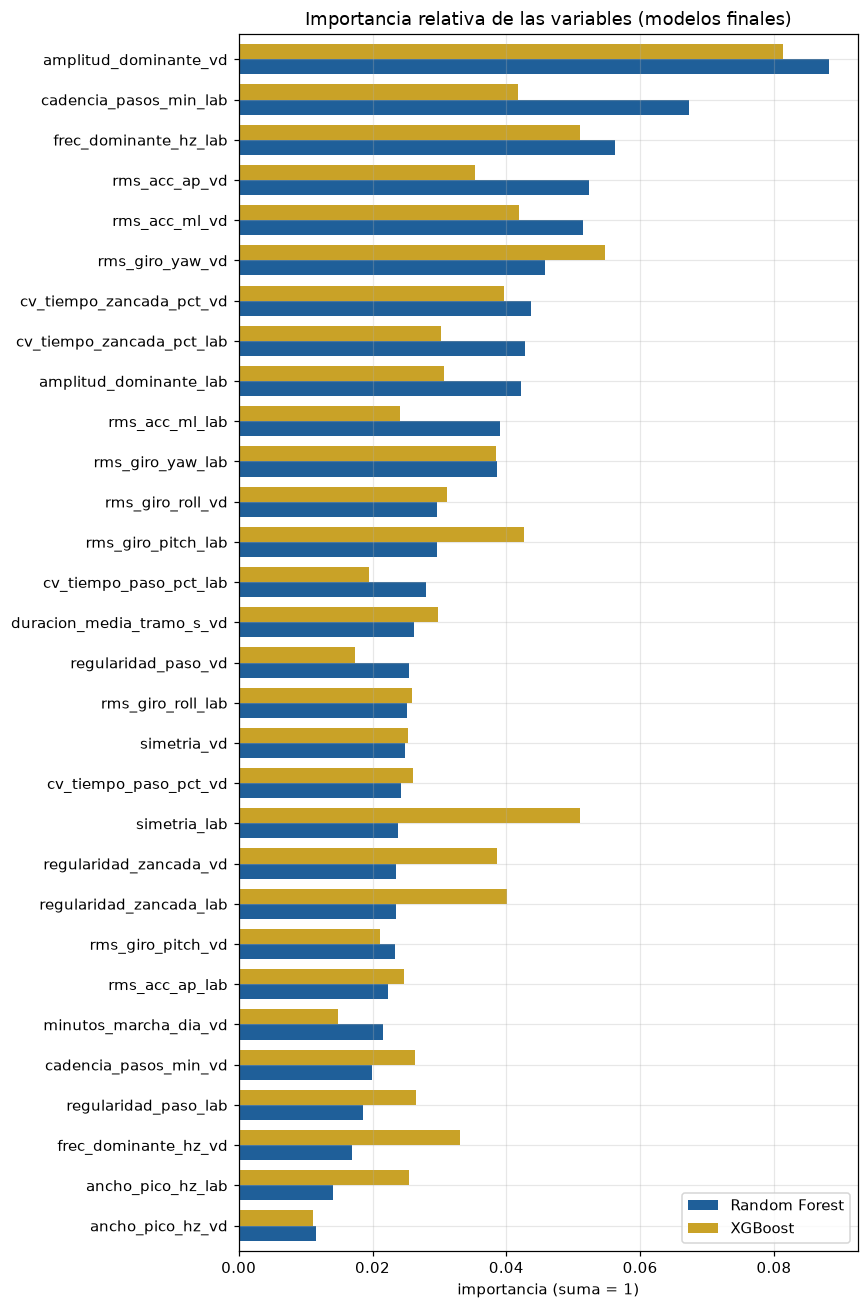

In [10]:
random_forest.fit(X, y)
xgb.fit(X, y)

importancia = pd.DataFrame({
    "Random Forest": random_forest[-1].feature_importances_,
    "XGBoost": xgb[-1].feature_importances_,
}, index=VARIABLES)
importancia = importancia / importancia.sum()          # para que ambas sumen 1 y se puedan comparar
importancia = importancia.sort_values("Random Forest")

fig, eje = plt.subplots(figsize=(8, 0.35 * len(VARIABLES) + 1.5))
importancia.plot.barh(ax=eje, width=0.75, color=["#1f5f99", "#c9a227"])
eje.set(title="Importancia relativa de las variables (modelos finales)", xlabel="importancia (suma = 1)")
fig.tight_layout()
fig.savefig(FIGURAS / f"modelos_importancia{SUFIJO}.png", dpi=150)
importancia.sort_values("Random Forest", ascending=False).round(3)

## 9. Guardar los modelos (checkpoints)

Se guardan con `joblib` junto con un archivo de información: qué variables necesita cada modelo y en qué orden, sus parámetros, las métricas de validación y las versiones de las librerías. Sin eso, un modelo guardado no se puede volver a usar con seguridad.

In [11]:
joblib.dump(random_forest, MODELOS / f"random_forest{SUFIJO}.joblib")
joblib.dump(xgb, MODELOS / f"xgboost{SUFIJO}.joblib")

info = {
    "fecha": datetime.now().isoformat(timespec="seconds"),
    "datos": f"datos/procesados/{ARCHIVOS[DATOS]}",
    "personas": int(len(datos)),
    "variables_en_orden": VARIABLES,
    "etiqueta": "cae (1 = cae, 0 = no cae)",
    "validacion": f"{N_PARTICIONES} particiones estratificadas x {N_REPETICIONES} repeticiones, semilla {SEMILLA}",
    "metricas_validacion": {m: {k: round(float(v), 4) for k, v in resumen.loc[m].items()}
                            for m in ("Random Forest", "XGBoost")},
    "parametros": {"Random Forest": {k: v for k, v in random_forest[-1].get_params().items()
                                     if k in ("n_estimators", "min_samples_leaf", "class_weight")},
                   "XGBoost": {k: v for k, v in xgb[-1].get_params().items()
                               if k in ("n_estimators", "learning_rate", "max_depth", "subsample", "colsample_bytree")}},
    "versiones": {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
                  "xgboost": xgboost.__version__, "numpy": np.__version__, "pandas": pd.__version__},
}
(MODELOS / f"info_modelos{SUFIJO}.json").write_text(json.dumps(info, indent=2, ensure_ascii=False), encoding="utf-8")
print("Guardados:", *sorted(p.name for p in MODELOS.iterdir()), sep="\n  ")

Guardados:
  info_lstm.json
  info_modelos.json
  info_modelos_combinado.json
  info_modelos_vida_diaria.json
  lstm.pt
  random_forest.joblib
  random_forest_combinado.joblib
  random_forest_vida_diaria.joblib
  xgboost.joblib
  xgboost_combinado.joblib
  xgboost_vida_diaria.joblib


In [12]:
# Prueba: cargar el modelo guardado y usarlo, como se hará en la Etapa 2
cargado = joblib.load(MODELOS / f"random_forest{SUFIJO}.joblib")
info_cargada = json.loads((MODELOS / f"info_modelos{SUFIJO}.json").read_text(encoding="utf-8"))
ejemplo = datos.sample(3, random_state=SEMILLA)
prob = cargado.predict_proba(ejemplo[info_cargada["variables_en_orden"]])[:, 1]
pd.DataFrame({"registro": ejemplo["registro"], "grupo real": ejemplo["grupo"],
              "probabilidad de caer": prob.round(2)})

,registro,grupo real,probabilidad de caer
50,fl023_base,Cae,0.66
56,fl030_base,Cae,0.70
0,co001_base,No cae,0.10


## 10. Resumen para el informe

Esta celda escribe el resumen con los números de esta ejecución.

In [13]:
def linea(m):
    f = lambda c: f"{resumen.loc[m, c + '_mean']:.2f} ± {resumen.loc[m, c + '_std']:.2f}".replace(".", ",")
    return (f"{m}: exactitud {f('exactitud')}, sensibilidad {f('sensibilidad')}, especificidad "
            f"{f('especificidad')}, F1 {f('f1')}, AUC {f('auc')}")

mejor = max(("Random Forest", "XGBoost"), key=lambda m: resumen.loc[m, "auc_mean"])
print(f"* Datos: {DATOS}, {len(datos)} personas ({int(y.sum())} caen y {int((y == 0).sum())} no caen) y {len(VARIABLES)} variables.")
print(f"* Validación: cruzada estratificada de {N_PARTICIONES} partes, repetida {N_REPETICIONES} veces "
      f"({N_PARTICIONES * N_REPETICIONES} pruebas por modelo); una fila por persona, sin fuga de datos entre sujetos.")
for m in orden:
    print("* " + linea(m))
print(f"* El modelo con mayor AUC promedio fue {mejor}. La comparación formal y la selección se hacen en la sub-etapa 1.4.")
print(f"* Variables más importantes (Random Forest): "
      f"{', '.join(importancia['Random Forest'].sort_values(ascending=False).index[:3])}.")

* Datos: combinado, 62 personas (27 caen y 35 no caen) y 30 variables.
* Validación: cruzada estratificada de 5 partes, repetida 10 veces (50 pruebas por modelo); una fila por persona, sin fuga de datos entre sujetos.
* Sin modelo: exactitud 0,57 ± 0,02, sensibilidad 0,00 ± 0,00, especificidad 1,00 ± 0,00, F1 0,00 ± 0,00, AUC 0,50 ± 0,00
* Solo frec_dominante_hz_lab: exactitud 0,68 ± 0,10, sensibilidad 0,50 ± 0,18, especificidad 0,82 ± 0,14, F1 0,57 ± 0,18, AUC 0,70 ± 0,13
* Solo TUG: exactitud 0,64 ± 0,13, sensibilidad 0,31 ± 0,17, especificidad 0,90 ± 0,16, F1 0,41 ± 0,20, AUC 0,63 ± 0,17
* Random Forest: exactitud 0,62 ± 0,10, sensibilidad 0,52 ± 0,19, especificidad 0,69 ± 0,15, F1 0,53 ± 0,15, AUC 0,62 ± 0,15
* XGBoost: exactitud 0,56 ± 0,10, sensibilidad 0,39 ± 0,17, especificidad 0,69 ± 0,17, F1 0,42 ± 0,16, AUC 0,55 ± 0,14
* El modelo con mayor AUC promedio fue Random Forest. La comparación formal y la selección se hacen en la sub-etapa 1.4.
* Variables más importantes (Random F

In [14]:
# Comparación entre fuentes de datos (aparece cuando ya ejecutaste el notebook con más de una opción de DATOS)
filas = []
for opcion in ARCHIVOS:
    ruta = RESULTADOS / f"metricas_modelos{'' if opcion == 'laboratorio' else '_' + opcion}.csv"
    if ruta.exists():
        r = pd.read_csv(ruta, index_col=0)
        for m in ("Random Forest", "XGBoost"):
            if m in r.index:
                filas.append({"datos": opcion, "modelo": m, "AUC": f"{r.loc[m, 'auc_mean']:.3f} ± {r.loc[m, 'auc_std']:.3f}",
                              "sensibilidad": f"{r.loc[m, 'sensibilidad_mean']:.3f}",
                              "especificidad": f"{r.loc[m, 'especificidad_mean']:.3f}"})
pd.DataFrame(filas) if filas else "Aún no hay resultados de otras fuentes de datos."

,datos,modelo,AUC,sensibilidad,especificidad
0,laboratorio,Random Forest,0.677 ± 0.137,0.602,0.610
1,laboratorio,XGBoost,0.644 ± 0.153,0.549,0.635
2,vida_diaria,Random Forest,0.622 ± 0.164,0.500,0.715
3,vida_diaria,XGBoost,0.609 ± 0.157,0.490,0.710
4,combinado,Random Forest,0.618 ± 0.145,0.523,0.689
5,combinado,XGBoost,0.548 ± 0.142,0.386,0.691


**Interpretación** (complétalo con tus palabras después de leer el resumen):

* ¿Los modelos superan a la referencia sin modelo y a la variable simple? ¿Y al TUG?
* ¿La sensibilidad es suficiente para una herramienta de prevención?
* Referencia de la literatura: Altunkaya (2024) obtuvo 82,2 % de exactitud con las mismas caminatas, pero con otras variables y otro esquema de validación, por lo que la comparación es solo orientativa.
* **Siguiente paso:** LSTM con las señales limpias (notebook 04) y comparación formal de los tres modelos (sub-etapa 1.4).